In [ ]:
##Attention and hidden states (very briefly)

# Attention is how we get or build context from the static embeddings that any model stores
# Attention is run multiple times in a model; GPT 2 --> 12x
# Affter attention, we run outputs through a feedforward network (Rosenblatt, Jed Dobson)
# ^ All of the above produces a hidden state
# THen, finally, we pass all of the above (x12) througha linear layer, or "unembedding layer"

# Model outputs.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

In [3]:
checkpoint = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint)
torch.manual_seed(5167)
torch.set_grad_enabled(False)
model.eval()



Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [78]:
tokenizer.pad_token = tokenizer.eos_token
text = "The work of art in the age of mechanical"
inputs = tokenizer(text, return_tensors="pt").to(model.device)
outputs = model(**inputs)

In [79]:
logits = outputs.logits
print("Shape of logits:", list(logits.shape)) # BAtch, num token, ....

Shape of logits: [1, 9, 50257]


In [80]:
assert inputs["input_ids"].size(1) == logits.size(1), "Unmatched size"
assert model.config.vocab_size == logits.size(2), "Unmatched size"

In [81]:
logits = logits[0, -1,  :]

In [82]:
# logits: raw, unnormalizzed scores from the model, which indicate what the model thinks
# should be the next tokens.


In [83]:
# Softmax
logits

tensor([-105.1062, -102.9467, -110.2262,  ..., -107.7944, -110.2417,
        -106.6088])

In [84]:
torch.exp(torch.tensor([8])) #e^8

tensor([2980.9580])

In [85]:
z = torch.tensor([1.25, -0.3, 0.87])
z -= z.max()

exp = torch.exp(z)
sigma_z = exp/exp.sum()
sigma_z

tensor([0.5274, 0.1119, 0.3607])

In [86]:
sigma_z.sum()

tensor(1.)

<Axes: >

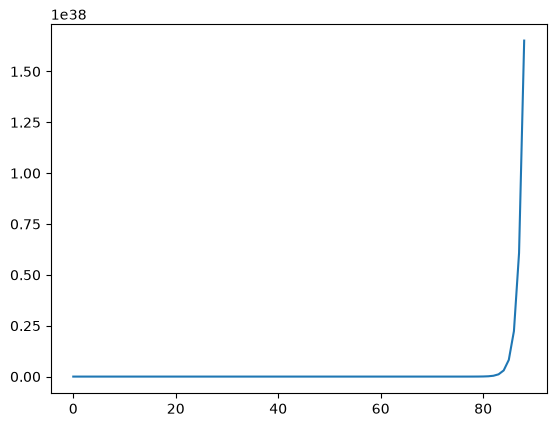

In [87]:
A =  torch.arange(1000)
exp_A = torch.exp(A)
sns.lineplot(x=A.numpy(), y=exp_A.numpy())

In [88]:
# Convert the logits via Softmax to a probability distribution
probs = F.softmax(logits, dim=-1)
probs

tensor([8.0518e-06, 6.9787e-05, 4.8120e-08,  ..., 5.4757e-07, 4.7379e-08,
        1.7920e-06])

In [89]:
# whats the next most likely token?
index = torch.argmax(probs).item()
token = tokenizer.decode(index)
print("Most likely token:", repr(token)) # Input --> output 

Most likely token: ' and'


In [90]:
# LLMs are deterministic! Argmax is taking the highest value to the response.

print("Most likely token:", repr(token))

Most likely token: ' and'


Most likely token: ' and'
              token  probability
0            ' and'     0.068005
1    ' engineering'     0.053864
2            ' art'     0.035112
3               ','     0.019451
4     ' technology'     0.017647
5         ' design'     0.017391
6   ' reproduction'     0.016982
7       ' progress'     0.012711
8      ' computers'     0.010714
9        ' science'     0.010286
10       ' devices'     0.009528
11     ' invention'     0.008981
12       ' systems'     0.007832
13      ' painting'     0.007796
14     ' sculpture'     0.007311
15   ' photography'     0.007004
16  ' intelligence'     0.006651
17         ' media'     0.005468
18          ' work'     0.005447
19         ' typew'     0.005386
20    ' production'     0.005177
21         ' power'     0.005141
22     ' keyboards'     0.005102
23            'ity'     0.004710
24    ' automation'     0.004459


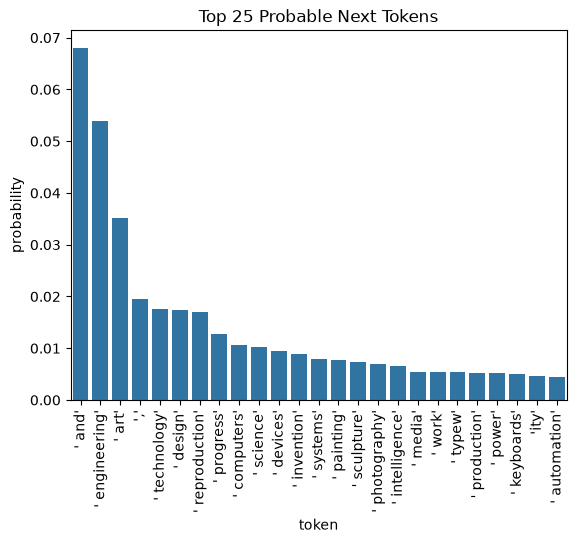

In [91]:
idx = torch.argmax(probs).item()
print("Most likely token:", repr(tokenizer.decode(idx)))

# Top-25
k = 25
top_probs, top_indices = torch.topk(probs, k)
top_tokens = [repr(tokenizer.decode(i.item())) for i in top_indices]
top_df = pd.DataFrame({"token": top_tokens, "probability": top_probs.numpy()})
print(top_df)

# 
fig, ax = plt.subplots()
sns.barplot(top_df, x="token", y="probability", ax=ax)
ax.tick_params(axis='x', rotation=90)
ax.set_title("Top 25 Probable Next Tokens")
plt.show()

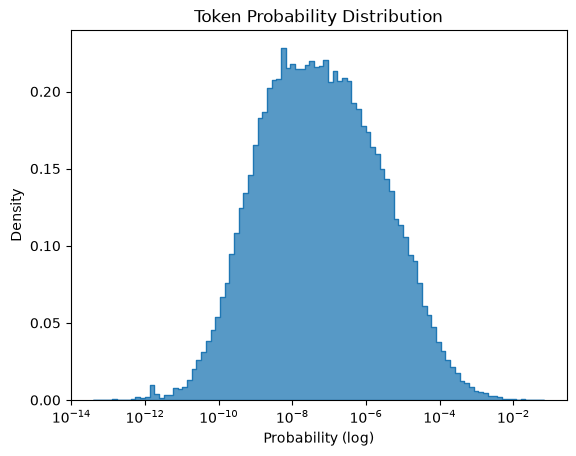

In [93]:
fig, ax = plt.subplots()
sns.histplot(
    probs.detach().cpu().numpy(),
    stat="density",
    element="step",
    log_scale=True,
    ax=ax
)
ax.set(title="Token Probability Distribution", xlabel="Probability (log)")
plt.show()

In [105]:
# sampling: make a decision w.r.t the next token.


# 1. greedy decoding.
def greedy_decoding(probs):
    """Perform greedy decoding.

    Parameters
    ----------
    probs : torch.Tensor, shape (vocab_size,)
        Token probabilities

    Returns
    -------
    int
        Selected token ID
    """
    idx = torch.argmax(probs)

    return idx.item()

In [108]:
for _ in range(5):
    idx = greedy_decoding(probs)
    token = tokenizer.decode(idx)
    print(repr(text + token))



'The work of art in the age of mechanical and'
'The work of art in the age of mechanical and'
'The work of art in the age of mechanical and'
'The work of art in the age of mechanical and'
'The work of art in the age of mechanical and'


In [112]:

# 2. multinominal sampling: treates probilities as exactly that: probabiliies, such that a token with probabilty .6
# will be chosen 60% of the time, a token with prob 0.001 will be chosen.
#quite rarely.
def multinomial_sampling(probs):
    """Perform multinomial sampling.

    Parameters
    ----------
    probs : torch.Tensor, shape (vocab_size,)
        Token probabilities

    Returns
    -------
    int
        Sampled token ID
    """
    idx = torch.multinomial(probs, num_samples=1)

    return idx.item()

for _ in range(5):
    idx = multinomial_sampling(probs)
    token = tokenizer.decode(idx)
    print(repr(text + token))

'The work of art in the age of mechanical complexity'
'The work of art in the age of mechanical compos'
'The work of art in the age of mechanical and'
'The work of art in the age of mechanical commerce'
'The work of art in the age of mechanical sche'


In [121]:
# 3. Top-k sampling: limits the candidate pool tot he top k most probable tokens.
## initialize a vector 0 prob and assign values from probs to indicies that correspond to the topk V.


def topk_filtering(probs, k=50):
    """Filter a probability distribution to only the top-k tokens.

    Parameters
    ----------
    probs : torch.Tensor, shape (vocab_size,)
        Token probabilities
    k : int
        Top token pool size

    Returns
    -------
    torch.Tensor, shape (vocab_size,)
        Filtered probabilities

    Raises
    ------
    ValueError
        If k is less than 0
    """
    if k <= 0:
        raise ValueError("k must be greater than 0")

    k = min(k, probs.numel())
    values, indices = torch.topk(probs, k=k)

    # Initialize vector of 0 probabilities and assign values from probs to 
    # indices that correspond to the top-k values
    filtered = torch.zeros_like(probs)
    filtered[indices] = probs[indices]

    # Normalize probabilities
    filtered = filtered / filtered.sum()

    return filtered



topk_probs = topk_filtering(probs)

for _ in range(5):
    idx = multinomial_sampling(topk_probs)
    token = tokenizer.decode(idx)
    print(repr(text + token))

'The work of art in the age of mechanical art'
'The work of art in the age of mechanical progress'
'The work of art in the age of mechanical systems'
'The work of art in the age of mechanical communication'
'The work of art in the age of mechanical engineering'


<Axes: ylabel='Count'>

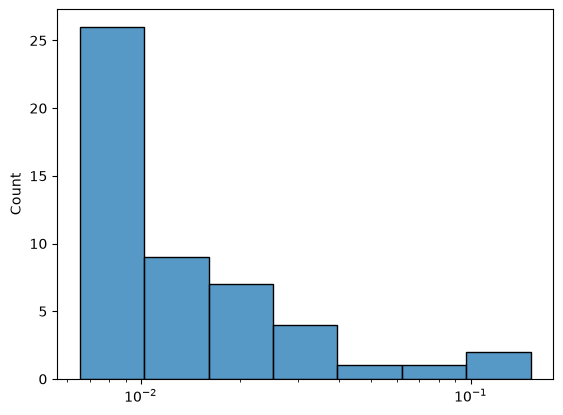

In [122]:
sns.histplot(topk_probs.detach().cpu().numpy(), log_scale=True)

In [119]:
# 4. Top-p sampling, or nucleus sampling: limits the candidate pool by the cumulative
# probability of tokens. Instead of setting a hard hnumber k, you dynamically set the
# site of your token pool based on the cumulative probability you want.
#
# Holtzmann (2019): how do you limit repetition in model outputs?


def topp_filtering(probs, p=0.9):
    """Filter a probability distribution using top-p/nucleus filtering.

    Parameters
    ----------
    probs : torch.Tensor, shape (vocab_size,)
        Token probabilities
    p : float
        Cumulative probability

    Returns
    -------
    torch.Tensor, shape (vocab_size,)
        Filtered probabilities

    Raises
    ------
    ValueError
        If p is less than or equal to 0, or greather than 1
    """
    if not 0 < p <= 1:
        raise ValueError("p must be in the interval (0, 1]")

    values, indices = torch.sort(probs, descending=True)
    cumulative = torch.cumsum(values, dim=0)

    # Index of the first token where cumulative probability >= p. Add 1 to keep
    # tokens up to and including the cutoff
    p = torch.tensor(p, device=probs.device, dtype=probs.dtype)
    cutoff = torch.searchsorted(cumulative, p).item() + 1
    candidate_indices = indices[:cutoff]

    # Normalize probabilities
    filtered = torch.zeros_like(probs)
    filtered[candidate_indices] = probs[candidate_indices]

    filtered = filtered / filtered.sum()

    return filtered



    
    topk_probs = topk_filtering(probs)

for _ in range(5):
    idx = multinomial_sampling(topk_probs)
    token = tokenizer.decode(idx)
    print(repr(text + token))

'The work of art in the age of mechanical and'
'The work of art in the age of mechanical engineering'
'The work of art in the age of mechanical invention'
'The work of art in the age of mechanical design'
'The work of art in the age of mechanical calcul'


<Axes: ylabel='Count'>

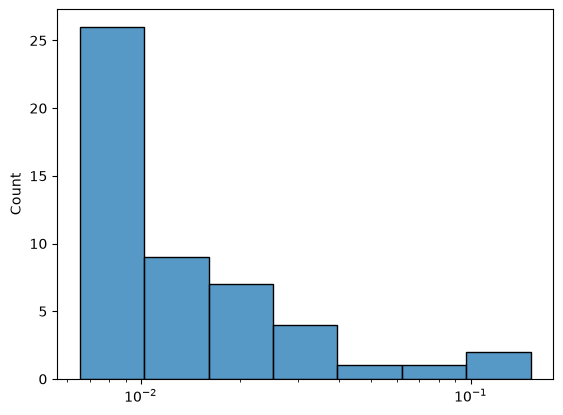

In [127]:

# 5. Temperature scaling reshapes the underlying.

# logits / t
# t = temperature (0, inf)
# - t < 1: making the model outputs more deterministic, aka closer to greedy decoding
# - t = 1: no effect
# - t > 1: make model outputs more random
#
# Modifying the probability distribution by either sharpening (t < 1) or flattening it (t > 1)
#
# Temperature scheduling: during model trainig, modify temprature
#
# Derives from statistical physics, entropy, Shannon (And kolmogorov ;D)
#
### Higher temperature would leads to flattening the distribution of outputs. 

def temperature_scaling(logits, temperature=1.0):
    """Perform temperature scaling.

    Parameters
    ----------
    logits : torch.Tensor
        Output logits, shape (vocab_size,)
    temperature : float
        Scaling factor. Higher values make the distribution flatter; lower
        values make it sharper

    Returns
    -------
    torch.Tensor, shape (vocab_size,)
        Probabilities after temperature scaling

    Raises
    ------
    ValueError
        If temperature is below 0
    """
    if temperature <= 0:
        raise ValueError("temperature must be greater than 0")

    scaled = logits / temperature
    probs = F.softmax(scaled, dim=-1)

    return probs

In [128]:
temp_probs = temperature_scaling(logits, temperature=1.5)

for _ in range(5):
    idx = multinomial_sampling(temp_probs)
    token = tokenizer.decode(idx)
    print(repr(text + token))

'The work of art in the age of mechanical history'
'The work of art in the age of mechanical humanity'
'The work of art in the age of mechanical elements'
'The work of art in the age of mechanical sciences'
'The work of art in the age of mechanical senses'


In [130]:
def get_sampling_distribution(logits, greedy=False, temperature=1.0, k=None, p=None):
    """Get a sampling distribution."""
    probs = temperature_scaling(logits, temperature=temperature)

    if greedy:
        index = greedy_decoding(probs)
        probs = torch.zeros_like(probs)
        probs[index] = 1.0

        return probs

    if k is not None:
        probs = topk_filtering(probs, k=k)

    if p is not None: probs = topp_filtering(probs, p=p)

    return probs

distribution = get_sampling_distribution(logits, temperature=1.2, k=100, p=0.9)
for _ in range(5):
    index = multinomial_sampling(distribution)
    token = tokenizer.decode(index)
    print(repr(text + token))
    

'The work of art in the age of mechanical technology'
'The work of art in the age of mechanical photography'
'The work of art in the age of mechanical and'
'The work of art in the age of mechanical progress'
'The work of art in the age of mechanical and'


In [131]:
configs = {
    "greedy": dict(greedy=True),
    "multinomial": dict(),
    "temp=0.7": dict(temperature=0.7),
    "temp=1.3": dict(temperature=1.3),
    "top-k=50": dict(k=50),
    "top-p=0.9": dict(p=0.90),
    "top-k=50, top-p=0.9": dict(k=50, p=0.9),
    "temp=0.7, top-p=0.9": dict(temperature=0.7, p=0.9),
    "temp=1.3, top-p=0.9": dict(temperature=1.3, p=0.9),
}

for key, values in configs.items():
    print("Settings:", key)
    distribution = get_sampling_distribution(logits, **values)

    index = multinomial_sampling(distribution)
    token = tokenizer.decode(index)
    print(repr(text + token))

    print()


Settings: greedy
'The work of art in the age of mechanical and'

Settings: multinomial
'The work of art in the age of mechanical complexity'

Settings: temp=0.7
'The work of art in the age of mechanical intelligence'

Settings: temp=1.3
'The work of art in the age of mechanical.('

Settings: top-k=50
'The work of art in the age of mechanical design'

Settings: top-p=0.9
'The work of art in the age of mechanical typew'

Settings: top-k=50, top-p=0.9
'The work of art in the age of mechanical engineering'

Settings: temp=0.7, top-p=0.9
'The work of art in the age of mechanical art'

Settings: temp=1.3, top-p=0.9
'The work of art in the age of mechanical micro'



In [144]:
new_tokens = 10
for name, config in configs.items():
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    seq = inputs["input_ids"]

    for _ in range(new_tokens):
        seq_outputs = model(input_ids=seq)

        seq_logits = seq_outputs.logits[0, -1, :]
        sampling_probs = get_sampling_distribution(seq_logits, **config)
        index = multinomial_sampling(sampling_probs)

        ## Append the sampled token ID, shape (1, seq_len)
        next_token = torch.tensor([[index]], device=seq.device)
        seq = torch.cat([seq, next_token], dim=1)

    generated = tokenizer.decode(seq[0])

    print("Config:", name)
    print("    Text:", repr(generated), flush=True)

Config: greedy
    Text: 'The work of art in the age of mechanical and electronic devices is not limited to the use of'
Config: multinomial
    Text: 'The work of art in the age of mechanical reproduction as well as modelling is still being developed,'
Config: temp=0.7
    Text: 'The work of art in the age of mechanical proof has been incredibly successful. It has been shown'
Config: temp=1.3
    Text: 'The work of art in the age of mechanical technologies allows industries through proposed approaches openness and metamorph'
Config: top-k=50
    Text: 'The work of art in the age of mechanical-digital interfaces was in a state of flux.'
Config: top-p=0.9
    Text: 'The work of art in the age of mechanical elements, which include digital and mobile devices, is'
Config: top-k=50, top-p=0.9
    Text: 'The work of art in the age of mechanical science has always been on the brink of collapse,'
Config: temp=0.7, top-p=0.9
    Text: 'The work of art in the age of mechanical reproduction and th